# Figure S — receptor levels are not predictive of phospho-signaling (Reviewer 2, point 2)

Model-independent evidence for why mechanistic integration helped only for EGFR transcript levels.

* **A** Receptor transcript/protein levels vs. baseline phospho-ERBB2 (CyTOF `p.HER2`, Y1248; EGF condition, t = 0, built like the encoder's `cytof_init` features). Open circles: baseline KNN-imputed as in `cytof_init`.
* **B** Pearson correlation of receptor levels with baseline pERBB2 and with the EGF-induced response (max over the EGF time course minus baseline) of the four model observables. The CyTOF panel has no phospho-EGFR or phospho-ERBB3 channel, so the EGF responses stand in as context. \* Benjamini–Hochberg q < 0.05 over the 30 pairs.
* **C** Random-forest importance of receptor levels for the CyTOF dynamics (estimator, targets and preprocessing of `select_features.py`), as the percentile among all candidate features of the modality, per CV split.
* **D** What the pipeline's own first RFE round (`HVGRFE_*`) does with each receptor: excluded before ranking (missingness filter, HVG prefilter) or ranked among the 501 HVG candidates.
* **E** How far each receptor survives the pipeline's full RFE: the smallest selection of the Fig. 1C feature-count scan (`HVGRFE_<N>_permute`, CV splits) that still contains it, read from the pipeline's feature files in `features/` (skipped if they are absent).
* **F** EGFR transcript among all transcripts: per transcript, its correlation with EGFR transcript vs. its correlation with each EGF-induced response, across cell lines.

Heavy step: panels C/D refit 120 random forests (about 25 min at low priority with 3 workers). Results are cached under `eval/EGFR_MAPK__logobs/dream_cytof/receptor_evidence/`; set `RECOMPUTE_RF = True` to refit.

In [1]:
import importlib
import sys
import warnings
from pathlib import Path

import matplotlib
import matplotlib.patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Ensure project root and figures_paper/ are on sys.path
_project_root = next(
    (_p for _p in (Path.cwd(), *Path.cwd().parents) if (_p / "common.py").is_file()),
    Path.cwd().parent,
)
for _p in (_project_root, _project_root / "figures_paper"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

warnings.filterwarnings("ignore")

import figure_config

importlib.reload(figure_config)
from figure_config import (
    CYTOF_MARKER_LABELS,
    FONTSIZE,
    LW_MEDIUM,
    LW_THIN,
    MODALITY_COLORS,
    configure_axis_spines,
)

import receptor_evidence

importlib.reload(receptor_evidence)
from receptor_evidence import (
    MODALITIES,
    MODALITY_LABELS,
    RECEPTORS,
    RESPONSE_LABELS,
    SPLITS,
    check_hvg_replication,
    coexpression_summary,
    correlation_summary,
    first_round_status,
    load_petab_tables,
    load_rf_importances,
    receptor_label,
    receptor_ranks,
    rfe_survival,
    zero_importance_rates,
)

RECOMPUTE_RF = False
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## Load data and compute correlations

In [2]:
tables = load_petab_tables()
corr = correlation_summary(tables)
levels, baseline, readouts = corr["levels"], corr["baseline"], corr["readouts"]
print(f"{len(corr['samples'])} cell lines; baseline pERBB2 measured in "
      f"{baseline['measured'].sum()}, KNN-imputed in {(~baseline['measured']).sum()}")
print("Cell lines with each receptor level:")
print(levels.notna().sum().unstack().rename(index=MODALITY_LABELS))

63 cell lines; baseline pERBB2 measured in 49, KNN-imputed in 14
Cell lines with each receptor level:
            EGFR  ERBB2  ERBB3
protein       59     62     33
transcript    63     63     63


### Receptor level vs. baseline pERBB2

In [3]:
corr["baseline_correlations"].round(3)

,subset,receptor,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,"all cell lines, encoder baseline",EGFR transcript,63,0.120,0.347,0.087,0.499
1,"all cell lines, encoder baseline",ERBB2 transcript,63,0.172,0.179,0.190,0.135
2,"all cell lines, encoder baseline",ERBB3 transcript,63,0.143,0.264,-0.043,0.737
3,"all cell lines, encoder baseline",EGFR protein,59,0.149,0.259,0.225,0.087
4,"all cell lines, encoder baseline",ERBB2 protein,62,0.233,0.068,0.149,0.248
5,"all cell lines, encoder baseline",ERBB3 protein,33,-0.162,0.367,-0.203,0.257
6,measured baseline only,EGFR transcript,49,0.115,0.431,0.056,0.704
7,measured baseline only,ERBB2 transcript,49,0.318,0.026,0.351,0.013
8,measured baseline only,ERBB3 transcript,49,0.242,0.094,0.019,0.898
9,measured baseline only,EGFR protein,46,0.071,0.639,0.175,0.245


### Transcript vs. protein level of each receptor

In [4]:
corr["transcript_vs_protein"].round(4)

,gene,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,EGFR,59,0.4376,0.0005,0.5396,0.0000
1,ERBB2,62,0.7658,0.0000,0.6937,0.0000
2,ERBB3,33,0.2835,0.1099,0.2455,0.1685


### Receptor level vs. baseline pERBB2 and EGF-induced responses (BH over 30 pairs)

In [5]:
corr["readout_correlations"].drop(columns=["modality", "gene"]).round(4)

,receptor,readout,n,pearson_r,pearson_p,spearman_rho,spearman_p,pearson_q,spearman_q
0,EGFR transcript,baseline pERBB2,63,0.1204,0.3471,0.0868,0.4986,0.5480,0.6800
1,EGFR transcript,pERBB2_Y1248_obs,49,0.5876,0.0000,0.6383,0.0000,0.0001,0.0000
2,EGFR transcript,pERK_Y204_obs,63,0.4731,0.0001,0.4103,0.0008,0.0006,0.0039
3,EGFR transcript,pMEK_S222_obs,63,0.4841,0.0001,0.5300,0.0000,0.0006,0.0001
4,EGFR transcript,pRPS6KA1_S380_obs,63,0.5742,0.0000,0.5230,0.0000,0.0000,0.0001
5,ERBB2 transcript,baseline pERBB2,63,0.1717,0.1785,0.1903,0.1352,0.4120,0.3381
6,ERBB2 transcript,pERBB2_Y1248_obs,49,-0.0255,0.8619,-0.1410,0.3338,0.8916,0.5270
7,ERBB2 transcript,pERK_Y204_obs,63,-0.0534,0.6778,-0.1101,0.3905,0.7673,0.5579
8,ERBB2 transcript,pMEK_S222_obs,63,-0.1050,0.4128,-0.1505,0.2390,0.5898,0.4530
9,ERBB2 transcript,pRPS6KA1_S380_obs,63,-0.1754,0.1692,-0.2256,0.0754,0.4120,0.2262


### Partial correlations given EGFR transcript level
Context for the associations in panel B that are not EGFR transcript.

In [6]:
corr["partial_given_egfr_transcript"].round(4)

,receptor,readout,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,ERBB2 transcript,baseline pERBB2,63,0.2053,0.1093,0.2310,0.0709
1,ERBB2 transcript,pERBB2_Y1248_obs,49,0.0380,0.7974,-0.0171,0.9079
2,ERBB2 transcript,pERK_Y204_obs,63,0.0614,0.6355,0.0244,0.8506
3,ERBB2 transcript,pMEK_S222_obs,63,0.0041,0.9745,0.0235,0.8559
4,ERBB2 transcript,pRPS6KA1_S380_obs,63,-0.0585,0.6517,-0.0724,0.5762
5,ERBB3 transcript,baseline pERBB2,63,0.2393,0.0611,0.0180,0.8897
6,ERBB3 transcript,pERBB2_Y1248_obs,49,0.0690,0.6415,-0.0942,0.5244
7,ERBB3 transcript,pERK_Y204_obs,63,-0.2527,0.0476,-0.2021,0.1152
8,ERBB3 transcript,pMEK_S222_obs,63,-0.2953,0.0198,-0.1631,0.2052
9,ERBB3 transcript,pRPS6KA1_S380_obs,63,-0.1208,0.3498,-0.1465,0.2560


## Panel A — receptor level vs. baseline pERBB2

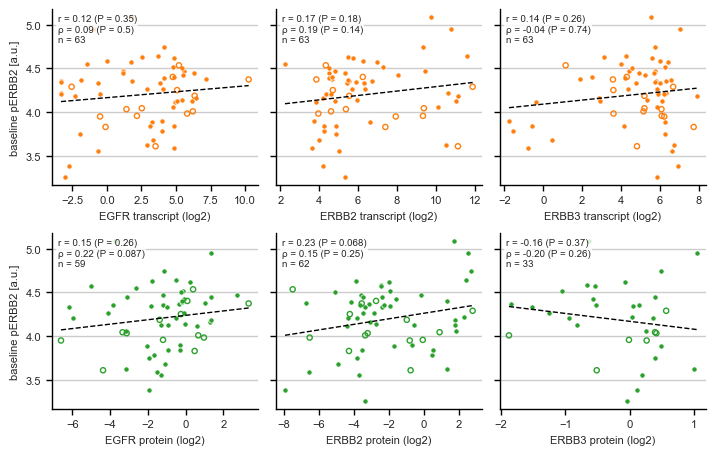

In [7]:
def annotate_corr(ax, stats_row):
    ax.text(
        0.03,
        0.97,
        f"r = {stats_row['pearson_r']:.2f} (P = {stats_row['pearson_p']:.2g})\n"
        f"\u03c1 = {stats_row['spearman_rho']:.2f} (P = {stats_row['spearman_p']:.2g})\n"
        f"n = {stats_row['n']}",
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=FONTSIZE - 1,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8, "pad": 1},
        zorder=5,
    )


baseline_corr = corr["baseline_correlations"].query(
    "subset == 'all cell lines, encoder baseline'"
).set_index("receptor")
y_label = "baseline " + CYTOF_MARKER_LABELS["p.ERBB2"]

fig_a, axes_a = plt.subplots(2, 3, figsize=(7.2, 4.6), sharey=True)
for i, modality in enumerate(MODALITIES):
    color = MODALITY_COLORS[MODALITY_LABELS[modality]]
    for j, gene in enumerate(RECEPTORS):
        ax = axes_a[i, j]
        x = levels[(modality, gene)]
        y = baseline["baseline pERBB2"]
        measured = baseline["measured"]
        ax.scatter(x[measured], y[measured], s=14, color=color, edgecolor="white", linewidth=LW_THIN)
        ax.scatter(x[~measured], y[~measured], s=14, facecolor="none", edgecolor=color, linewidth=LW_MEDIUM)
        ok = x.notna() & y.notna()
        slope, intercept = np.polyfit(x[ok], y[ok], 1)
        xs = np.linspace(x[ok].min(), x[ok].max(), 2)
        ax.plot(xs, slope * xs + intercept, color="black", linewidth=LW_MEDIUM, linestyle="--")
        annotate_corr(ax, baseline_corr.loc[receptor_label(modality, gene)])
        ax.set_xlabel(f"{gene} {MODALITY_LABELS[modality]} (log2)", fontsize=FONTSIZE)
        if j == 0:
            ax.set_ylabel(y_label, fontsize=FONTSIZE)
        configure_axis_spines(ax)
fig_a.tight_layout()
fig_a.savefig("figS_receptor_panelA.pdf", bbox_inches="tight")
plt.show()

## Panel B — receptor level vs. pERBB2 and EGF-induced responses

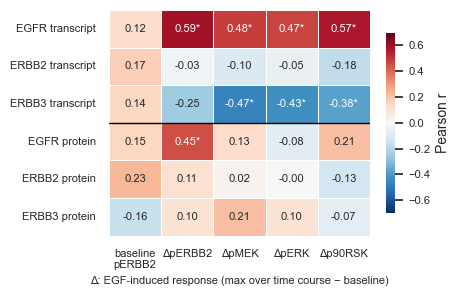

n per cell:
readout           baseline pERBB2  pERBB2_Y1248_obs  pMEK_S222_obs  pERK_Y204_obs  pRPS6KA1_S380_obs
receptor                                                                                            
EGFR transcript                63                49             63             63                 63
ERBB2 transcript               63                49             63             63                 63
ERBB3 transcript               63                49             63             63                 63
EGFR protein                   59                46             59             59                 59
ERBB2 protein                  62                48             62             62                 62
ERBB3 protein                  33                26             33             33                 33


In [8]:
rc = corr["readout_correlations"]
rows = [receptor_label(m, g) for m in MODALITIES for g in RECEPTORS]
cols = list(RESPONSE_LABELS)
r_mat = rc.pivot(index="receptor", columns="readout", values="pearson_r").loc[rows, cols]
q_mat = rc.pivot(index="receptor", columns="readout", values="pearson_q").loc[rows, cols]
n_mat = rc.pivot(index="receptor", columns="readout", values="n").loc[rows, cols]
annot = r_mat.map(lambda r: f"{r:.2f}") + q_mat.map(lambda q: "*" if q < 0.05 else "")

fig_b, ax_b = plt.subplots(figsize=(4.6, 3.0))
sns.heatmap(
    r_mat,
    ax=ax_b,
    cmap="RdBu_r",
    vmin=-0.7,
    vmax=0.7,
    annot=annot,
    fmt="",
    annot_kws={"fontsize": FONTSIZE},
    linewidths=LW_THIN,
    linecolor="white",
    cbar_kws={"label": "Pearson r", "shrink": 0.8},
)
ax_b.set_xticklabels([RESPONSE_LABELS[c] for c in cols], rotation=0, fontsize=FONTSIZE)
ax_b.set_yticklabels(rows, rotation=0, fontsize=FONTSIZE)
ax_b.set_xlabel("\u0394: EGF-induced response (max over time course \u2212 baseline)", fontsize=FONTSIZE)
ax_b.set_ylabel("")
ax_b.axhline(len(RECEPTORS), color="black", linewidth=LW_MEDIUM)
fig_b.tight_layout()
fig_b.savefig("figS_receptor_panelB.pdf", bbox_inches="tight")
plt.show()
print("n per cell:")
print(n_mat)

## Random-forest importance

Same targets (KNN-imputed, centered `cytof_dynamic`), preprocessing (missingness filter, KNN imputation, mean-centering, scaling) and estimator (`RandomForestRegressor(max_features=0.8)`, impurity importance above 500 features) as the first RFE round in `select_features.py`.

* `candidate_set == "all"`: every feature of the modality that passes the missingness filter, importance averaged over 5 seeds (42 = pipeline seed).
* `candidate_set == "hvg"`: the pipeline's actual first round (`HVGRFE_*`: HVG prefilter as fixed in commit 50bd9e1, i.e. the 501 most variable features without a low-mean step), importance averaged over the same 5 seeds (single forests are too noisy to rank by).

In [9]:
importances, receptor_filters = load_rf_importances(recompute=RECOMPUTE_RF, tables=tables)
ranks = receptor_ranks(importances)
ranks.round(4)

,split,context,candidate_set,gene,receptor,n_features,n_nonzero,n_seeds,importance,rank,percentile
0,BT20,proteomics,all,EGFR,EGFR protein,6179,5725,5,0.0001,3934.0,36.3327
1,BT20,proteomics,all,ERBB2,ERBB2 protein,6179,5725,5,0.0002,1302.0,78.9286
2,BT20,proteomics,all,ERBB3,ERBB3 protein,6179,5725,5,NaN,NaN,NaN
3,BT20,proteomics,hvg,EGFR,EGFR protein,501,501,5,0.0019,139.0,72.2555
4,BT20,proteomics,hvg,ERBB2,ERBB2 protein,501,501,5,0.0010,380.0,24.1517
...,...,...,...,...,...,...,...,...,...,...,...
67,all,transcriptomics,all,ERBB2,ERBB2 transcript,16562,10132,5,0.0001,4249.0,74.3449
68,all,transcriptomics,all,ERBB3,ERBB3 transcript,16562,10132,5,0.0001,2954.0,82.1640
69,all,transcriptomics,hvg,EGFR,EGFR transcript,501,501,5,0.0028,48.0,90.4192
70,all,transcriptomics,hvg,ERBB2,ERBB2 transcript,501,501,5,NaN,NaN,NaN


### Which receptors reach the random forest
`passes_missingness_filter`: < 30 % missing across the training cell lines (`load_data`). `variance_rank` / `in_hvg_set`: the HVG prefilter of `HVGRFE_*` (keep the 501 most variable).

In [10]:
receptor_filters

,gene,variance_rank,in_hvg_set,passes_missingness_filter,split,context,n_candidates
0,EGFR,275.0,True,True,BT20,transcriptomics,16562
1,ERBB2,1049.0,False,True,BT20,transcriptomics,16562
2,ERBB3,1537.0,False,True,BT20,transcriptomics,16562
3,EGFR,152.0,True,True,BT20,proteomics,6179
4,ERBB2,25.0,True,True,BT20,proteomics,6179
5,ERBB3,NaN,False,False,BT20,proteomics,6179
6,EGFR,316.0,True,True,HCC1500,transcriptomics,16562
7,ERBB2,1035.0,False,True,HCC1500,transcriptomics,16562
8,ERBB3,1528.0,False,True,HCC1500,transcriptomics,16562
9,EGFR,128.0,True,True,HCC1500,proteomics,6177


### Replication check
Features selected by the pipeline (`features/…/HVGRFE_*`, if present locally) must lie inside the replicated HVG sets. Only feature files regenerated after the HVG fix (commit 50bd9e1) can match; older files were selected from the buggy prefilter.

In [11]:
replication = check_hvg_replication(importances)
if len(replication):
    n_off = (replication["n_outside_replicated_hvg"] > 0).sum()
    print(f"{len(replication)} feature files, {n_off} with features outside the replicated HVG sets")
replication if len(replication) else "no saved HVGRFE feature files found"

170 feature files, 0 with features outside the replicated HVG sets


,file,n_selected,n_outside_replicated_hvg,receptors_selected
0,proteomics__BT20__HVGRFE_1024_permute.csv,501,0,"[EGFR, ERBB2]"
1,proteomics__BT20__HVGRFE_10_permute.csv,10,0,[]
2,proteomics__BT20__HVGRFE_128_permute.csv,128,0,[]
3,proteomics__BT20__HVGRFE_12_permute.csv,12,0,[]
4,proteomics__BT20__HVGRFE_16_permute.csv,16,0,[]
...,...,...,...,...
165,transcriptomics__UACC3199__HVGRFE_4_permute.csv,4,0,[]
166,transcriptomics__UACC3199__HVGRFE_512_permute.csv,501,0,[EGFR]
167,transcriptomics__UACC3199__HVGRFE_64_permute.csv,64,0,[]
168,transcriptomics__UACC3199__HVGRFE_6_permute.csv,6,0,[]


## Panel C — random-forest importance percentile among all features of the modality

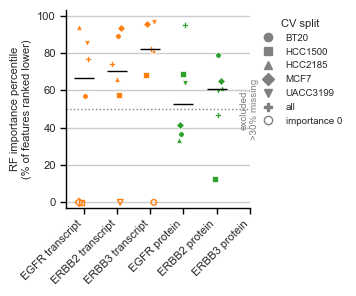

In [12]:
all_ranks = ranks[ranks["candidate_set"] == "all"]
order = [receptor_label(m, g) for m in MODALITIES for g in RECEPTORS]
split_markers = dict(zip(SPLITS, ["o", "s", "^", "D", "v", "P"]))

fig_c, ax_c = plt.subplots(figsize=(3.6, 3.0))
rng = np.random.default_rng(0)
for k, label in enumerate(order):
    sub = all_ranks[all_ranks["receptor"] == label]
    color = MODALITY_COLORS[label.split()[1]]
    if sub["percentile"].isna().all():
        ax_c.text(k, 50, "excluded:\n>30% missing", rotation=90, ha="center", va="center",
                  fontsize=FONTSIZE - 1, color="grey")
        continue
    for _, row in sub.iterrows():
        unused = row["importance"] == 0  # never used for a split in any of the forests
        ax_c.scatter(k + rng.uniform(-0.15, 0.15), row["percentile"], s=16,
                     facecolor="none" if unused else color, edgecolor=color if unused else "white",
                     marker=split_markers[row["split"]], linewidth=LW_MEDIUM if unused else LW_THIN)
    ax_c.hlines(sub["percentile"].median(), k - 0.3, k + 0.3, color="black", linewidth=LW_MEDIUM)
# the median feature of a modality sits at the 50th percentile by construction
ax_c.axhline(50, color="grey", linestyle=":", linewidth=LW_MEDIUM, zorder=0)
ax_c.set_xticks(range(len(order)))
ax_c.set_xticklabels(order, rotation=45, ha="right", fontsize=FONTSIZE)
ax_c.set_ylim(-3, 103)
ax_c.set_ylabel("RF importance percentile\n(% of features ranked lower)", fontsize=FONTSIZE)
ax_c.legend(
    handles=[plt.Line2D([], [], marker=m, linestyle="", color="grey", label=s)
             for s, m in split_markers.items()]
    + [plt.Line2D([], [], marker="o", linestyle="", markerfacecolor="none", color="grey",
                  label="importance 0")],
    title="CV split", frameon=False, fontsize=FONTSIZE - 1, bbox_to_anchor=(1.0, 1.0), loc="upper left",
)
configure_axis_spines(ax_c)
fig_c.tight_layout()
fig_c.savefig("figS_receptor_panelC.pdf", bbox_inches="tight")
plt.show()

### How often a single forest leaves a feature unused
Share of the 30 single forests per modality (6 splits × 5 seeds, full candidate set) in which the feature has zero importance, compared with the average feature.

In [13]:
zero_importance_rates(importances).round(3)

,context,feature,zero_rate
0,proteomics,all features,0.572
1,proteomics,EGFR protein,0.533
2,proteomics,ERBB2 protein,0.533
3,transcriptomics,all features,0.814
4,transcriptomics,EGFR transcript,0.800
5,transcriptomics,ERBB2 transcript,0.667
6,transcriptomics,ERBB3 transcript,0.633


## Panel D — receptors in the pipeline's first RFE round (`HVGRFE_*`)

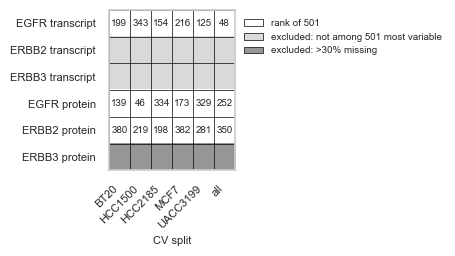

status,ranked,excluded: not among 501 most variable,excluded: >30% missing
receptor,,,
EGFR transcript,6,0,0
ERBB2 transcript,0,6,0
ERBB3 transcript,0,6,0
EGFR protein,6,0,0
ERBB2 protein,6,0,0
ERBB3 protein,0,0,6


In [14]:
status = first_round_status(ranks, receptor_filters)
status_colors = {
    "ranked": "#ffffff",
    "excluded: not among 501 most variable": "#d9d9d9",
    "excluded: >30% missing": "#969696",
}
codes = {s: i for i, s in enumerate(status_colors)}
grid = status.pivot(index="receptor", columns="split", values="status").loc[order, list(SPLITS)]
rank_grid = status.pivot(index="receptor", columns="split", values="rank").loc[order, list(SPLITS)]

fig_d, ax_d = plt.subplots(figsize=(4.6, 2.6))
ax_d.imshow(
    grid.replace(codes).to_numpy(dtype=float),
    cmap=matplotlib.colors.ListedColormap(list(status_colors.values())),
    vmin=-0.5,
    vmax=len(codes) - 0.5,
    aspect="auto",
)
for i, receptor in enumerate(order):
    for j, split in enumerate(SPLITS):
        if grid.loc[receptor, split] == "ranked":
            ax_d.text(j, i, f"{rank_grid.loc[receptor, split]:.0f}", ha="center", va="center",
                      fontsize=FONTSIZE - 1)
ax_d.set_xticks(range(len(SPLITS)), labels=SPLITS, rotation=45, ha="right", fontsize=FONTSIZE)
ax_d.set_yticks(range(len(order)), labels=order, fontsize=FONTSIZE)
ax_d.set_xticks(np.arange(len(SPLITS) + 1) - 0.5, minor=True)
ax_d.set_yticks(np.arange(len(order) + 1) - 0.5, minor=True)
ax_d.grid(which="minor", color="black", linewidth=LW_THIN)
ax_d.grid(which="major", visible=False)
ax_d.tick_params(which="minor", length=0)
ax_d.set_xlabel("CV split", fontsize=FONTSIZE)
ax_d.legend(
    handles=[matplotlib.patches.Patch(facecolor=c, edgecolor="black", linewidth=LW_THIN,
                                      label="rank of 501" if s == "ranked" else s)
             for s, c in status_colors.items()],
    frameon=False, fontsize=FONTSIZE - 1, bbox_to_anchor=(1.0, 1.0), loc="upper left",
)
fig_d.tight_layout()
fig_d.savefig("figS_receptor_panelD.pdf", bbox_inches="tight")
plt.show()
status.groupby(["receptor", "status"], sort=False).size().unstack(fill_value=0).loc[order]

## Panel E — how far receptors survive the full RFE (Fig. 1C feature-count scan)
Smallest `HVGRFE_<N>_permute` selection per CV split that still contains the receptor (`nested`: every larger selection contains it too). Dashed line: size of the final models' feature set (`BEST_FEATURE_SETS`). Needs the `figure1c` feature files produced with the HVG fix (on NEMO: dated 2 Nov 2026 or later). The replication check above is necessary but not sufficient for that: older transcript selections often lie inside the fixed HVG set too.

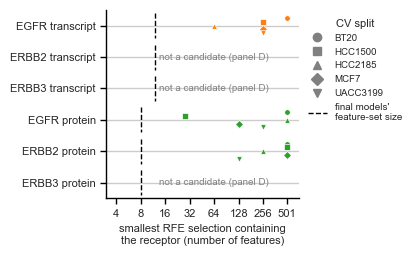

split,BT20,HCC1500,HCC2185,MCF7,UACC3199
receptor,,,,,
EGFR transcript,501.0,256.0,64.0,256.0,256.0
ERBB2 transcript,NaN,NaN,NaN,NaN,NaN
ERBB3 transcript,NaN,NaN,NaN,NaN,NaN
EGFR protein,501.0,28.0,501.0,128.0,256.0
ERBB2 protein,501.0,501.0,256.0,501.0,128.0
ERBB3 protein,NaN,NaN,NaN,NaN,NaN


In [15]:
survival = rfe_survival()
if survival.empty:
    print("no figure1c HVGRFE feature files under features/")
else:
    cv_splits = list(survival["split"].unique())
    offsets = dict(zip(cv_splits, np.linspace(-0.24, 0.24, len(cv_splits))))
    scan_ticks = [4, 8, 16, 32, 64, 128, 256, 501]

    fig_e, ax_e = plt.subplots(figsize=(4.2, 2.6))
    for i, label in enumerate(order):
        sub = survival[survival["receptor"] == label]
        color = MODALITY_COLORS[label.split()[1]]
        ax_e.vlines(sub["final_size"].iloc[0], i - 0.4, i + 0.4, color="black", linestyle="--",
                    linewidth=LW_MEDIUM)
        if sub["smallest_selection"].isna().all():
            ax_e.text(64, i, "not a candidate (panel D)", ha="center", va="center",
                      fontsize=FONTSIZE - 1, color="grey")
            continue
        for _, row in sub.iterrows():
            ax_e.scatter(row["smallest_selection"], i + offsets[row["split"]], s=16, color=color,
                         edgecolor="white", linewidth=LW_THIN, marker=split_markers[row["split"]])
    ax_e.set_xscale("log", base=2)
    ax_e.set_xlim(3, 700)
    ax_e.set_xticks(scan_ticks, labels=[str(t) for t in scan_ticks], fontsize=FONTSIZE)
    ax_e.minorticks_off()
    ax_e.set_yticks(range(len(order)), labels=order, fontsize=FONTSIZE)
    ax_e.set_ylim(len(order) - 0.5, -0.5)  # same row order as panel D
    ax_e.set_xlabel("smallest RFE selection containing\nthe receptor (number of features)", fontsize=FONTSIZE)
    ax_e.legend(
        handles=[plt.Line2D([], [], marker=split_markers[s], linestyle="", color="grey", label=s)
                 for s in cv_splits]
        + [plt.Line2D([], [], color="black", linestyle="--", linewidth=LW_MEDIUM,
                      label="final models'\nfeature-set size")],
        title="CV split", frameon=False, fontsize=FONTSIZE - 1, bbox_to_anchor=(1.0, 1.0), loc="upper left",
    )
    configure_axis_spines(ax_e)
    fig_e.tight_layout()
    fig_e.savefig("figS_receptor_panelE.pdf", bbox_inches="tight")
    plt.show()
survival.pivot(index="receptor", columns="split", values="smallest_selection").reindex(order)

In [16]:
survival.groupby("receptor", sort=False).agg(
    smallest_median=("smallest_selection", "median"),
    smallest_min=("smallest_selection", "min"),
    smallest_max=("smallest_selection", "max"),
    nested_all=("nested", "all"),
    in_final_size_selection=("in_final_size_selection", "sum"),
).reindex(order)

,smallest_median,smallest_min,smallest_max,nested_all,in_final_size_selection
receptor,,,,,
EGFR transcript,256.0,64.0,501.0,True,0
ERBB2 transcript,NaN,NaN,NaN,True,0
ERBB3 transcript,NaN,NaN,NaN,True,0
EGFR protein,256.0,28.0,501.0,True,0
ERBB2 protein,501.0,128.0,501.0,True,0
ERBB3 protein,NaN,NaN,NaN,True,0


## Panel F — EGFR transcript among all transcripts
Each point (hexbin) is one of the transcripts that pass the missingness filter (the RF candidates), across all 63 cell lines. x: Pearson r with EGFR transcript; y: Pearson r with the EGF-induced response (n = 49 cell lines with a measured baseline). The annotation gives r across transcripts between x and y, and the rank of EGFR transcript itself among all transcripts by |r| with the response.

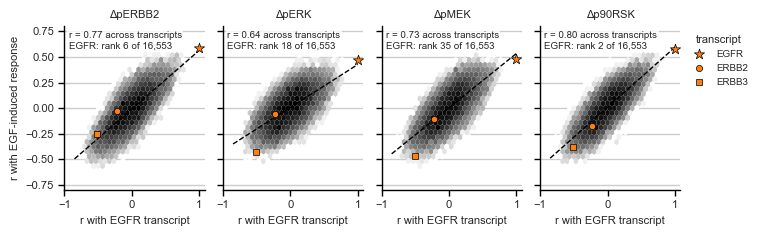

In [17]:
co = coexpression_summary(tables)
gc = co["gene_correlations"]
egfr_rank = co["egfr_rank"]
responses = [c for c in gc.columns if c != "EGFR transcript"]
others = gc.drop(index=list(RECEPTORS))
receptor_markers = {"EGFR": "*", "ERBB2": "o", "ERBB3": "s"}

fig_f, axes_f = plt.subplots(1, len(responses), figsize=(7.6, 2.4), sharex=True, sharey=True)
for ax, obs in zip(axes_f, responses):
    ax.hexbin(others["EGFR transcript"], others[obs], gridsize=30, bins="log", cmap="Greys",
              mincnt=1, linewidths=0, extent=(-1, 1, -0.8, 0.8))
    fit = gc.drop(index="EGFR")
    slope, intercept = np.polyfit(fit["EGFR transcript"], fit[obs], 1)
    xs = np.array([-0.85, 1.0])
    ax.plot(xs, slope * xs + intercept, color="black", linestyle="--", linewidth=LW_MEDIUM)
    for gene, marker in receptor_markers.items():
        ax.scatter(gc.loc[gene, "EGFR transcript"], gc.loc[gene, obs], marker=marker,
                   s=60 if marker == "*" else 20, color=MODALITY_COLORS["transcript"],
                   edgecolor="black", linewidth=LW_THIN, zorder=3, label=gene)
    rank = egfr_rank.set_index("target").loc[obs]
    ax.text(0.03, 0.97,
            f"r = {co['axis_agreement'][obs]:.2f} across transcripts\n"
            f"EGFR: rank {rank['rank']} of {rank['n_transcripts']:,}",
            transform=ax.transAxes, va="top", ha="left", fontsize=FONTSIZE - 1,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8, "pad": 1})
    ax.set_title(RESPONSE_LABELS[obs], fontsize=FONTSIZE)
    ax.set_xlabel("r with EGFR transcript", fontsize=FONTSIZE)
    ax.set_xlim(-1, 1.08)
    ax.set_ylim(-0.8, 0.8)
    configure_axis_spines(ax)
axes_f[0].set_ylabel("r with EGF-induced response", fontsize=FONTSIZE)
axes_f[-1].legend(title="transcript", frameon=False, fontsize=FONTSIZE - 1, bbox_to_anchor=(1.0, 1.0),
                  loc="upper left")
fig_f.tight_layout()
fig_f.savefig("figS_receptor_panelF.pdf", bbox_inches="tight")
plt.show()

### Co-expression partners and what the random forest is fitted to
`partners`: other transcripts with |r| ≥ 0.5, and the percentage of all transcripts with fewer. `egfr_rank`: rank of EGFR transcript among all transcripts by |r|, for the four EGF-induced responses and for the 96 RF targets of split `all` (the centered `cytof_dynamic` columns: four observables × three conditions × time points).

In [18]:
display(co["partners"].round(1))
display(co["axis_agreement"].round(3))
egfr_rank.groupby("target_set")["rank"].describe().round(0)

,n_partners,percentile,median_all_transcripts
FEATURE_ID,,,
EGFR,756,98.9,38.0
ERBB2,239,88.7,38.0
ERBB3,1217,99.9,38.0


pERBB2_Y1248_obs     0.765
pERK_Y204_obs        0.637
pMEK_S222_obs        0.727
pRPS6KA1_S380_obs    0.795
Name: r_across_transcripts, dtype: float64

,count,mean,std,min,25%,50%,75%,max
target_set,,,,,,,,
EGF-induced response,4.0,15.0,15.0,2.0,5.0,12.0,22.0,35.0
RF target (split all),96.0,3645.0,4800.0,1.0,304.0,1055.0,5604.0,16415.0


### Summary across splits (for the response letter)

In [19]:
summary = (
    ranks.groupby(["candidate_set", "receptor"], sort=False)
    .agg(
        n_features=("n_features", "median"),
        rank_median=("rank", "median"),
        rank_min=("rank", "min"),
        rank_max=("rank", "max"),
        percentile_median=("percentile", "median"),
        percentile_min=("percentile", "min"),
        percentile_max=("percentile", "max"),
        splits_ranked=("rank", "count"),
    )
)
summary.round(1)

n_features  rank_median  rank_min  rank_max  percentile_median  percentile_min  percentile_max  splits_ranked
candidate_set receptor                                                                                                                       
all           EGFR protein          6180.0       2919.5     297.0    4123.0               52.8            33.3            95.2              6
              ERBB2 protein         6180.0       2438.0    1302.0    5419.0               60.6            12.3            78.9              6
              ERBB3 protein         6180.0          NaN       NaN       NaN                NaN             NaN             NaN              0
hvg           EGFR protein           501.0        212.5      46.0     334.0               57.6            33.3            90.8              6
              ERBB2 protein          501.0        315.5     198.0     382.0               37.0            23.8            60.5              6
              ERBB3 protein          501.0          NaN       NaN       NaN                NaN             NaN             NaN              0
all           EGFR transcript      16562.0       5508.0    1010.0   10047.0               66.7             0.0            93.9              6
              ERBB2 transcript     16562.0       4945.5    1120.0    9935.0               70.1             0.0            93.2              6
              ERBB3 transcript     16562.0       2997.0     590.0   10026.0               81.9             0.0            96.4              6
hvg           EGFR transcript        501.0        176.5      48.0     343.0               64.8            31.5            90.4              6
              ERBB2 transcript       501.0          NaN       NaN       NaN                NaN             NaN             NaN              0
              ERBB3 transcript       501.0          NaN       NaN       NaN                NaN             NaN             NaN              0